In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
from scipy.spatial import cKDTree
from scipy.ndimage import map_coordinates

warnings.filterwarnings("ignore")
DATA, RES, FIG = Path(".."), Path("results"), Path("figures")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9})
tile_file = lambda t, band: DATA / f"LH_Mosaic_opt_tile_{t}_{band}_mos32.fits"
mosaic_header = fits.getheader(DATA / "mosaic.fits")
MNY, MNX = mosaic_header["NAXIS2"], mosaic_header["NAXIS1"]

In [2]:
X0, X1, Y0, Y1 = 2000, 6800, 9200, 13950     # cutout covering the mosaic plus a margin
SPLIT, ROW_OFFSET = 10500, 10400


def stitch(band):
    h43, h44 = fits.getheader(tile_file("4_3", band)), fits.getheader(tile_file("4_4", band))
    for k in ("CRVAL1", "CRVAL2", "CDELT1", "CDELT2", "CROTA2", "CRPIX1"):
        assert h43[k] == h44[k], f"tiles do not share the same grid ({k})"
    assert h43["CRPIX2"] - h44["CRPIX2"] == ROW_OFFSET
    d43 = fits.open(tile_file("4_3", band), memmap=True)[0].data
    d44 = fits.open(tile_file("4_4", band), memmap=True)[0].data
    out = np.full((Y1 - Y0, X1 - X0), np.nan, np.float32)
    out[:SPLIT - Y0] = d43[Y0:SPLIT, X0:X1]
    out[SPLIT - Y0:] = d44[SPLIT - ROW_OFFSET:Y1 - ROW_OFFSET, X0:X1]
    a = d43[10450:10550, X0:X1]; b = d44[10450 - ROW_OFFSET:10550 - ROW_OFFSET, X0:X1]
    same = np.mean(a[np.isfinite(a) & np.isfinite(b)] == b[np.isfinite(a) & np.isfinite(b)])
    h = h43.copy(); h["CRPIX1"] = h43["CRPIX1"] - X0; h["CRPIX2"] = h43["CRPIX2"] - Y0
    fits.PrimaryHDU(out, h).writeto(RES / f"tile_{band}_stitched.fits", overwrite=True)
    print(f"{band}: overlap rows identical in both tiles: {100 * same:.0f}%;  blank (NaN) pixels: {100 * np.isnan(out).mean():.2f}%")


for band in ("r", "i", "U"):
    stitch(band)

r: overlap rows identical in both tiles: 100%;  blank (NaN) pixels: 0.24%


i: overlap rows identical in both tiles: 100%;  blank (NaN) pixels: 0.23%


U: overlap rows identical in both tiles: 100%;  blank (NaN) pixels: 0.18%


In [3]:
ORDER = 3


def design(x, y):
    u, v = (np.asarray(x, float) - 1285) / 1285, (np.asarray(y, float) - 2305) / 2305      # scaled to about [-1, 1]
    return np.column_stack([u ** i * v ** j for i in range(ORDER + 1) for j in range(ORDER + 1 - i)])


def mosaic_to_tile(x, y):
    A = design(np.atleast_1d(x), np.atleast_1d(y))
    return A @ CX, A @ CY


tile_r = fits.getdata(RES / "tile_r_stitched.fits").astype(float)
wt = WCS(fits.getheader(RES / "tile_r_stitched.fits"))
cat = Table.read(RES / "catalogue.ecsv")
sel = (cat["snr"] > 30) & (cat["peak"] < 25000) & ~cat["near_mask"]
xm, ym = np.asarray(cat["x"][sel]), np.asarray(cat["y"][sel])
Xg, Yg = wt.all_world2pix(*WCS(mosaic_header).all_pix2world(xm, ym, 0), 0)

_, med, std = sigma_clipped_stats(tile_r[np.isfinite(tile_r)][::50])
src = DAOStarFinder(fwhm=3.5, threshold=10 * std, sharplo=0.2, sharphi=1.0, roundlo=-0.6, roundhi=0.6)(np.nan_to_num(tile_r - med))
xcol = "x_centroid" if "x_centroid" in src.colnames else "xcentroid"
ycol = "y_centroid" if "y_centroid" in src.colnames else "ycentroid"
Xt, Yt = np.asarray(src[xcol]), np.asarray(src[ycol])
tree = cKDTree(np.c_[Xt, Yt])

# coarse shift: most common offset between header-predicted and detected positions
d, j = tree.query(np.c_[Xg, Yg], distance_upper_bound=20); ok = np.isfinite(d)
H, xe, ye = np.histogram2d(Xt[j[ok]] - Xg[ok], Yt[j[ok]] - Yg[ok], bins=40, range=[[-20, 20], [-20, 20]])
i0, j0 = np.unravel_index(np.argmax(H), H.shape)
X, Y = Xg + 0.5 * (xe[i0] + xe[i0 + 1]), Yg + 0.5 * (ye[j0] + ye[j0 + 1])

for radius in (6, 3, 1.5, 1.0):
    d, j = tree.query(np.c_[X, Y], distance_upper_bound=radius); m = np.isfinite(d)
    keep = np.ones(m.sum(), bool)
    for _ in range(10):
        A = design(xm[m][keep], ym[m][keep])
        CX = np.linalg.lstsq(A, Xt[j[m]][keep], rcond=None)[0]; CY = np.linalg.lstsq(A, Yt[j[m]][keep], rcond=None)[0]
        resid = np.hypot(design(xm[m], ym[m]) @ CX - Xt[j[m]], design(xm[m], ym[m]) @ CY - Yt[j[m]])
        new = resid < max(3 * 1.4826 * np.median(resid[keep]), 0.3)
        if (new == keep).all():
            break
        keep = new
    X, Y = mosaic_to_tile(xm, ym)
    rms_arcsec = np.sqrt(np.mean(resid[keep] ** 2)) * 0.300
    print(f"matching radius {radius} px: {keep.sum()} sources used, rms residual {rms_arcsec:.3f} arcsec")

json.dump({"order": ORDER, "cx": CX.tolist(), "cy": CY.tolist(), "n_matches": int(keep.sum()), "rms_arcsec": float(rms_arcsec)},
          open(RES / "mosaic_to_tile_map.json", "w"), indent=1)

matching radius 6 px: 194 sources used, rms residual 0.199 arcsec
matching radius 3 px: 281 sources used, rms residual 0.211 arcsec
matching radius 1.5 px: 282 sources used, rms residual 0.182 arcsec
matching radius 1.0 px: 282 sources used, rms residual 0.151 arcsec


In [4]:
def tile_coords():
    Xa, Ya, J = (np.empty((MNY, MNX)) for _ in range(3))
    for y0 in range(0, MNY, 256):
        yy, xx = np.mgrid[y0:min(MNY, y0 + 256), 0:MNX].astype(float)
        sl = slice(y0, y0 + yy.shape[0]); e = 0.5
        a, b = mosaic_to_tile(xx.ravel(), yy.ravel())
        a1, b1 = mosaic_to_tile(xx.ravel() + e, yy.ravel()); a0, b0 = mosaic_to_tile(xx.ravel() - e, yy.ravel())
        a3, b3 = mosaic_to_tile(xx.ravel(), yy.ravel() + e); a2, b2 = mosaic_to_tile(xx.ravel(), yy.ravel() - e)
        Xa[sl], Ya[sl] = a.reshape(yy.shape), b.reshape(yy.shape)
        J[sl] = np.abs((a1 - a0) * (b3 - b2) - (a3 - a2) * (b1 - b0)).reshape(yy.shape)
    return Xa, Ya, J


Xa, Ya, J = tile_coords()
print(f"one mosaic pixel = {0.300 * np.sqrt(J.mean()):.4f} arcsec on average "
      f"(varies by {100 * (np.sqrt(J.max() / J.min()) - 1):.1f}% across the image because of optical distortion)")
for band in ("r", "i", "U"):
    t = fits.getdata(RES / f"tile_{band}_stitched.fits").astype(float)
    bad = ~np.isfinite(t)
    val = map_coordinates(np.where(bad, 0, t), [Ya, Xa], order=3, mode="constant", cval=np.nan)
    touches_bad = map_coordinates(bad.astype(float), [Ya, Xa], order=1, mode="constant", cval=1.0) > 0
    out = (val * J).astype(np.float32); out[touches_bad] = np.nan
    h = fits.Header()
    for k in ("CTYPE1", "CTYPE2", "CRVAL1", "CRVAL2", "CRPIX1", "CRPIX2", "CD1_1", "CD1_2", "CD2_1", "CD2_2", "PV2_1", "PV2_3", "EQUINOX"):
        if k in mosaic_header:
            h[k] = mosaic_header[k]
    h["FILTER"] = fits.getheader(RES / f"tile_{band}_stitched.fits")["FILTER"]
    h["COMMENT"] = "SWIRE Lockman tiles 4_3 + 4_4 resampled onto the mosaic.fits pixel grid (flux conserving)"
    fits.PrimaryHDU(out, h).writeto(RES / f"mosaic_equivalent_{band}.fits", overwrite=True)
    print(f"{band}: written results/mosaic_equivalent_{band}.fits")

one mosaic pixel = 0.2572 arcsec on average (varies by 4.1% across the image because of optical distortion)


r: written results/mosaic_equivalent_r.fits


i: written results/mosaic_equivalent_i.fits


U: written results/mosaic_equivalent_U.fits


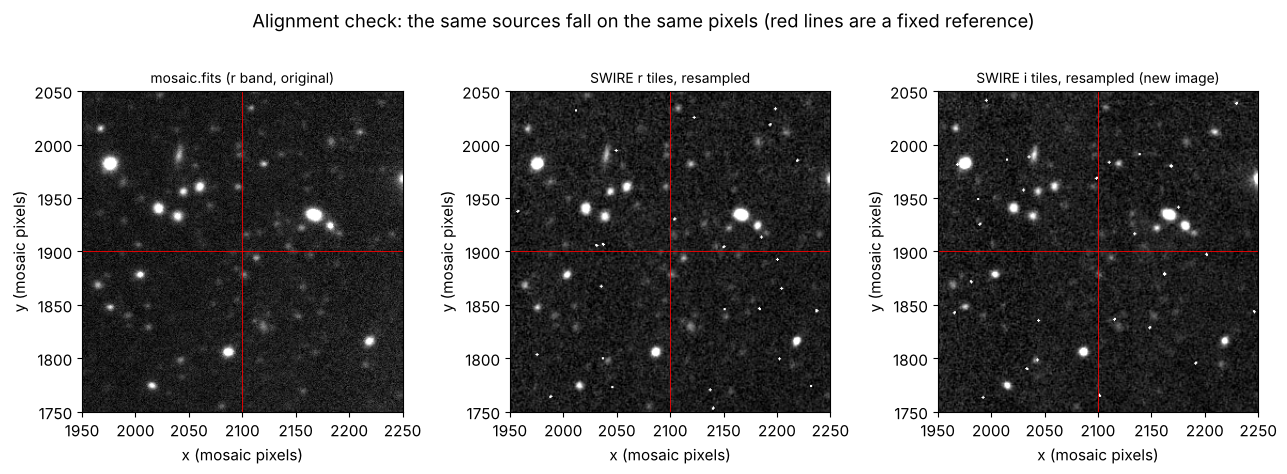

In [5]:
mos = fits.getdata(DATA / "mosaic.fits").astype(float)
imgs = [(mos, "mosaic.fits (r band, original)"), (fits.getdata(RES / "mosaic_equivalent_r.fits"), "SWIRE r tiles, resampled"),
        (fits.getdata(RES / "mosaic_equivalent_i.fits"), "SWIRE i tiles, resampled (new image)")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
sl = (slice(1750, 2050), slice(1950, 2250))
for ax, (img, title) in zip(axes, imgs):
    c = img[sl]; med = np.nanmedian(c); s = 1.4826 * np.nanmedian(np.abs(c - med))
    ax.imshow(c, origin="lower", cmap="gray", vmin=med - 2 * s, vmax=med + 15 * s, extent=[1950, 2250, 1750, 2050])
    ax.axvline(2100, color="r", lw=0.6); ax.axhline(1900, color="r", lw=0.6)
    ax.set_title(title, fontsize=10); ax.set_xlabel("x (mosaic pixels)"); ax.set_ylabel("y (mosaic pixels)")
fig.suptitle("Alignment check: the same sources fall on the same pixels (red lines are a fixed reference)")
fig.tight_layout(); fig.savefig(FIG / "07_alignment_check.png"); plt.show()

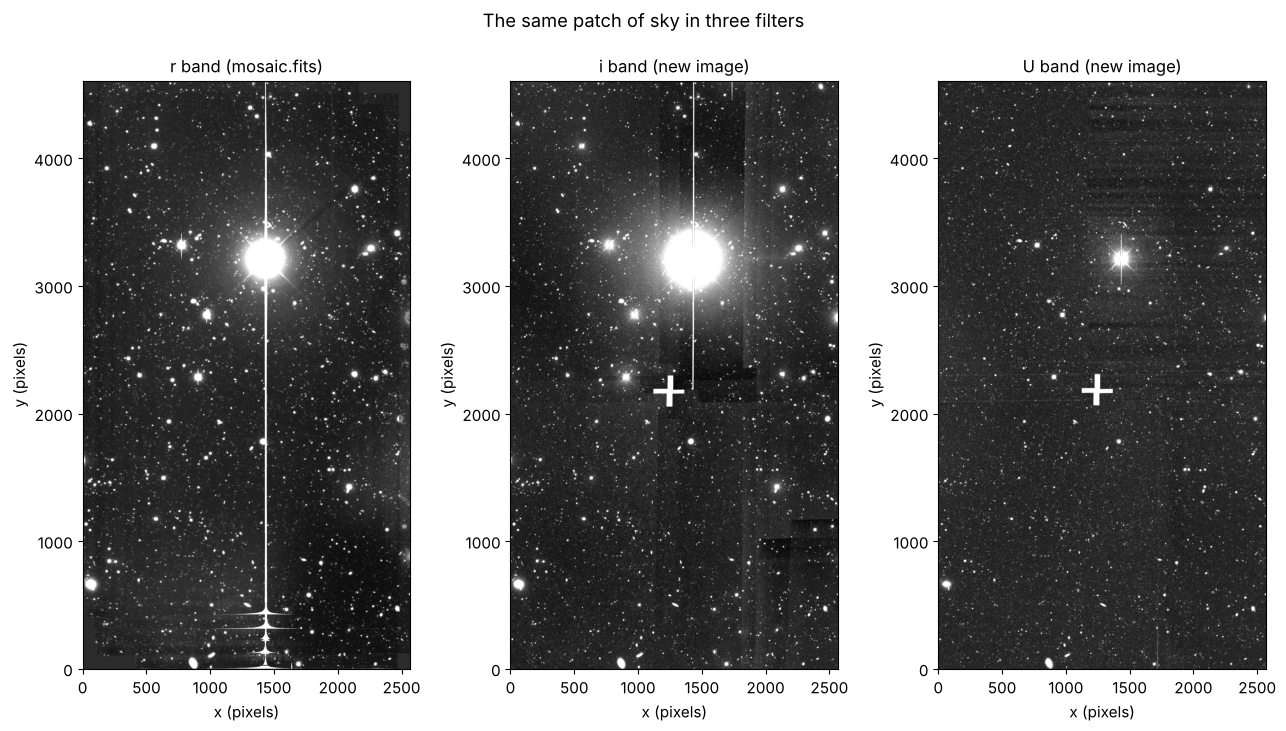

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 7.5))
full = imgs[:1] + [(imgs[2][0], "i band (new image)"), (fits.getdata(RES / "mosaic_equivalent_U.fits"), "U band (new image)")]
full[0] = (mos, "r band (mosaic.fits)")
for ax, (img, title) in zip(axes, full):
    finite = img[np.isfinite(img)][::37]; med = np.median(finite); s = 1.4826 * np.median(np.abs(finite - med))
    ax.imshow(img, origin="lower", cmap="gray", vmin=med - 2 * s, vmax=med + 10 * s)
    ax.set_title(title); ax.set_xlabel("x (pixels)"); ax.set_ylabel("y (pixels)")
fig.suptitle("The same patch of sky in three filters")
fig.tight_layout(); fig.savefig(FIG / "07_three_filters.png"); plt.show()